# 02 — Data Cleaning
**Pipeline stage:** `Data Validation → Data Cleaning → EDA → Statistical Analysis → Time-Series Analysis → Feature Engineering → Feature Selection → Regression Model → Anomaly Detection → Prediction → REST API`

This notebook takes the automatically-discovered organized metrology dataset produced
upstream (Notebook 01 — Data Understanding) and produces a **cleaned, harmonized
dataset** ready for exploratory analysis and feature engineering.

Every cleaning decision below is justified metrologically in the markdown immediately
preceding it, and **every row excluded is logged with an explicit reason** — nothing is
silently dropped, in line with ISO/IEC 17025 auditability requirements.

No filename, threshold, or column name is hardcoded: everything is read from
`config/config.yaml`, consistent with Notebook 01.

**Outputs:**
- `data/processed/ILA_cleaned.csv`
- `reports/quality/cleaning_exclusions_log.csv`
- `reports/quality/cleaning_summary.xlsx`
- Figures in `reports/figures/02_data_cleaning/`
- `logs/02_data_cleaning.log`


## 1. Imports

In [1]:
import sys
import re
import logging
import unicodedata
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 100)

plt.rcParams["figure.facecolor"] = "white"
sns.set_style("whitegrid")

print("Imports OK —", datetime.now().isoformat(timespec="seconds"))


Imports OK — 2026-08-22T12:52:26


## 2. Configuration

Same convention as Notebook 01: the project root is located by walking up from the
current working directory until `config/config.yaml` is found, so the notebook runs
identically whether launched from the project root or from `notebooks/`.


In [2]:
PROJECT_ROOT_CANDIDATES = [Path.cwd(), Path.cwd().parent]
project_root = None
for c in PROJECT_ROOT_CANDIDATES:
    if (c / "config" / "config.yaml").exists():
        project_root = c
        break
if project_root is None:
    raise FileNotFoundError(
        "Could not find config/config.yaml from the current working directory. "
        "Run this notebook from the project root or from notebooks/."
    )
sys.path.insert(0, str(project_root))

from src.utils.config import load_config  # noqa: E402

cfg = load_config()

DATA_INTERIM = project_root / cfg["paths"]["data_interim"]
DATA_PROCESSED = project_root / cfg["paths"]["data_processed"]
REPORTS_FIGURES = project_root / cfg["paths"]["reports_figures"] / "02_data_cleaning"
REPORTS_QUALITY = project_root / cfg["paths"]["reports_quality"]
LOGS_DIR = project_root / cfg["paths"]["logs"]

for d in [REPORTS_FIGURES, REPORTS_QUALITY, DATA_PROCESSED, LOGS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

EXPECTED_COLUMNS = cfg["expected_columns"]
EXCLUDE_KEYWORDS = cfg["dataset_discovery"]["exclude_keywords"]
SPLIT_KEYWORDS = cfg["dataset_discovery"]["split_keywords"]
MIN_YEAR = cfg["plausibility"]["min_year"]
MAX_YEAR = cfg["plausibility"]["max_year"]

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
    handlers=[
        logging.FileHandler(LOGS_DIR / "02_data_cleaning.log", mode="w"),
        logging.StreamHandler(sys.stdout),
    ],
)
logger = logging.getLogger("02_data_cleaning")

logger.info("Project root: %s", project_root)
logger.info("Expected columns: %s", EXPECTED_COLUMNS)


2026-08-22 12:52:26,614 | INFO | Project root: /home/claude/project2/metrology-ai-pipeline


2026-08-22 12:52:26,616 | INFO | Expected columns: ['id_instrument', 'lab', 'annee', 'point', 'consigne', 'valeur_reference', 'incertitude', 'EMT_basse', 'EMT_haute', 'min', 'max', 'conforme']


## 3. Load Dataset

### 3.1 Automatic dataset discovery

Identical discovery logic to Notebook 01 — **no filename is hardcoded**. Every CSV under
`data/interim/` and `data/processed/` is scored against the expected metrology schema
declared in `config.yaml`. Log/traceability/audit files are excluded by keyword, and the
notebook prefers the complete, non-split organized dataset — this is the dataset
cleaning decisions must be made on, upstream of any train/test split, so that the split
notebook (later in the pipeline) inherits an already-cleaned dataset rather than
re-deciding cleaning rules per split.


In [3]:
def score_candidate(csv_path: Path, expected_columns: list[str]) -> dict:
    '''Read only the header of a CSV and score it against the expected schema.'''
    try:
        header_df = pd.read_csv(csv_path, nrows=0)
    except Exception as e:
        return {"path": csv_path, "readable": False, "error": str(e), "score": -1}

    columns = list(header_df.columns)
    overlap = set(c.strip() for c in columns) & set(expected_columns)
    name_lower = csv_path.stem.lower()

    is_excluded = any(kw in name_lower for kw in EXCLUDE_KEYWORDS)
    is_split = any(kw in name_lower for kw in SPLIT_KEYWORDS)

    try:
        n_rows = sum(1 for _ in open(csv_path, encoding="utf-8-sig")) - 1
    except Exception:
        n_rows = -1

    return {
        "path": csv_path,
        "readable": True,
        "n_columns_found": len(columns),
        "n_expected_columns_matched": len(overlap),
        "matched_columns": sorted(overlap),
        "is_excluded_by_keyword": is_excluded,
        "is_split_or_augmented": is_split,
        "n_rows": n_rows,
    }


search_dirs = [DATA_INTERIM, DATA_PROCESSED]
candidate_files = []
for d in search_dirs:
    candidate_files.extend(sorted(d.glob("*.csv")))

logger.info("Found %d candidate CSV file(s) in %s", len(candidate_files), search_dirs)

candidates = [score_candidate(p, EXPECTED_COLUMNS) for p in candidate_files]
candidates_df = pd.DataFrame(candidates)
display(candidates_df[["path", "readable", "n_columns_found", "n_expected_columns_matched",
                        "is_excluded_by_keyword", "is_split_or_augmented", "n_rows"]])


2026-08-22 12:52:26,626 | INFO | Found 10 candidate CSV file(s) in [PosixPath('/home/claude/project2/metrology-ai-pipeline/data/interim'), PosixPath('/home/claude/project2/metrology-ai-pipeline/data/processed')]


,path,readable,n_columns_found,n_expected_columns_matched,is_excluded_by_keyword,is_split_or_augmented,n_rows
0,/home/claude/project2/metrology-ai-pipeline/da...,True,7,1,True,False,49
1,/home/claude/project2/metrology-ai-pipeline/da...,True,12,12,False,False,767
2,/home/claude/project2/metrology-ai-pipeline/da...,True,6,4,True,False,6
3,/home/claude/project2/metrology-ai-pipeline/da...,True,15,4,True,False,767
4,/home/claude/project2/metrology-ai-pipeline/da...,True,23,12,False,False,763
5,/home/claude/project2/metrology-ai-pipeline/da...,True,44,11,False,False,763
6,/home/claude/project2/metrology-ai-pipeline/da...,True,17,8,False,False,763
7,/home/claude/project2/metrology-ai-pipeline/da...,True,13,12,False,True,133
8,/home/claude/project2/metrology-ai-pipeline/da...,True,13,12,False,True,2109
9,/home/claude/project2/metrology-ai-pipeline/da...,True,13,12,False,True,528


In [4]:
# Selection rule (fully automatic, no filename hardcoded):
#  1. Keep only readable candidates.
#  2. Drop candidates excluded by keyword (log / tracabilite / audit / exclu files).
#  3. Among the remainder, prefer full (non split/augmented) datasets that match
#     the complete expected schema — cleaning decisions are made once, on the full
#     organized dataset, upstream of any split.
#  4. If no full dataset is found, fall back to the split dataset with the
#     highest schema match and highest row count.
valid = [c for c in candidates if c.get("readable") and not c.get("is_excluded_by_keyword")]
if not valid:
    raise RuntimeError("No valid metrology dataset candidate found in data/interim or data/processed.")

full_matches = [c for c in valid
                if c["n_expected_columns_matched"] == len(EXPECTED_COLUMNS)
                and not c["is_split_or_augmented"]]

if full_matches:
    chosen = max(full_matches, key=lambda c: c["n_rows"])
    logger.info("Selected FULL organized dataset (non-split): %s", chosen["path"].name)
else:
    chosen = max(valid, key=lambda c: (c["n_expected_columns_matched"], c["n_rows"]))
    logger.warning("No full non-split dataset found — falling back to: %s", chosen["path"].name)

DATASET_PATH = chosen["path"]
logger.info("DATASET SELECTED: %s (%d rows, %d/%d expected columns matched)",
            DATASET_PATH, chosen["n_rows"], chosen["n_expected_columns_matched"], len(EXPECTED_COLUMNS))

print(f"\n>>> Dataset automatically selected: {DATASET_PATH.relative_to(project_root)}\n")

df_raw = pd.read_csv(DATASET_PATH)
df = df_raw.copy()
n_rows_start = len(df)
logger.info("Loaded dataset with shape %s", df.shape)
print(f"Loaded shape: {df.shape}")
display(df.head())


2026-08-22 12:52:26,674 | INFO | Selected FULL organized dataset (non-split): ILA_donnees_organisees.csv


2026-08-22 12:52:26,676 | INFO | DATASET SELECTED: /home/claude/project2/metrology-ai-pipeline/data/interim/ILA_donnees_organisees.csv (767 rows, 12/12 expected columns matched)



>>> Dataset automatically selected: data/interim/ILA_donnees_organisees.csv

2026-08-22 12:52:26,680 | INFO | Loaded dataset with shape (767, 12)


Loaded shape: (767, 12)


,id_instrument,lab,annee,point,consigne,valeur_reference,incertitude,EMT_basse,EMT_haute,min,max,conforme
0,INST-03B-CHAMBREDEFERMENTATION,lab 03B,2020,1,NaN,24.10,0.07,24.0,26.0,24.03,24.17,conforme
1,INST-03B-CHAMBREDEFERMENTATION,lab 03B,2020,2,NaN,24.00,0.07,24.0,26.0,23.93,24.07,non conforme
2,INST-03B-CHAMBREDEFERMENTATION,lab 03B,2021,1,NaN,24.08,0.20,24.0,26.0,23.88,24.28,non conforme
3,INST-03B-CHAMBREDEFERMENTATION,lab 03B,2021,2,NaN,23.81,0.20,24.0,26.0,23.61,24.01,non conforme
4,INST-03B-CHAMBREDEFERMENTATION,lab 03B,2022,1,NaN,24.08,0.20,24.0,26.0,23.88,24.28,non conforme


## 4. Cleaning Steps

### 4.1 String & categorical normalization — `lab`

**Justification:** Notebook 01's laboratory-inconsistency check found that the same
physical laboratory is recorded under several raw text variants across calibration
campaigns (e.g. `lab 03B` vs `lab 03B-2025`, or `LAB 11B` vs `lab 11b`), because the
source Excel sheet names sometimes embed the campaign year and casing is inconsistent.
Without normalization, grouping by `lab` would incorrectly split one real laboratory
into several. The original column is kept and a normalized column is added, so no
information is lost.


In [5]:
def normalize_lab(s):
    s = str(s).strip().lower()
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode()
    s = re.sub(r"-?20\d{2}", "", s)          # drop trailing campaign-year suffixes like '-2025'
    s = re.sub(r"[^a-z0-9]", "", s)
    return s

df["lab_original"] = df["lab"]
df["lab_clean"] = df["lab"].apply(normalize_lab)

n_lab_before = df["lab"].nunique()
n_lab_after = df["lab_clean"].nunique()

lab_norm_summary = pd.DataFrame({
    "metric": ["distinct_lab_values_before", "distinct_lab_values_after_normalization"],
    "value": [n_lab_before, n_lab_after],
})
display(lab_norm_summary)
logger.info("lab normalization: %d raw variants collapsed into %d normalized labs", n_lab_before, n_lab_after)


,metric,value
0,distinct_lab_values_before,37
1,distinct_lab_values_after_normalization,20


2026-08-22 12:52:26,699 | INFO | lab normalization: 37 raw variants collapsed into 20 normalized labs


### 4.2 Type harmonization — `point`

**Justification:** Notebook 01's data dictionary found `point` mixes numeric-looking
strings (`'1'`, `'1.0'`) with genuine text labels (`'au fond'`, `'en avant'`,
`'milieu'`). These are not data-entry errors — some instruments are checked at named
physical positions rather than numbered points — so this is split into two explicit,
correctly-typed columns instead of forcing everything into one ambiguous type.


In [6]:
def to_numeric_point(v):
    try:
        return float(str(v).replace(",", "."))
    except (ValueError, TypeError):
        return np.nan

df["point_numeric"] = df["point"].apply(to_numeric_point)
df["point_label"] = df["point"].where(df["point_numeric"].isna(), np.nan)
df["point_type"] = np.where(df["point_numeric"].notna(), "numeric", "named_position")

display(df["point_type"].value_counts().to_frame("count"))
named_positions = sorted(df.loc[df["point_type"] == "named_position", "point"].unique())
print("Distinct named positions found:", named_positions)
logger.info("point harmonization: %d numeric, %d named-position rows; named positions=%s",
            (df["point_type"] == "numeric").sum(), (df["point_type"] == "named_position").sum(),
            named_positions)


,count
point_type,
numeric,731
named_position,36


Distinct named positions found: ['au fond', 'en avant', 'milieu']
2026-08-22 12:52:26,713 | INFO | point harmonization: 731 numeric, 36 named-position rows; named positions=['au fond', 'en avant', 'milieu']


### 4.3 Numeric type coercion

All measurement columns declared in `config.yaml` are (re-)coerced to numeric with
`errors="coerce"`. Any value that fails to convert is logged with concrete examples —
never silently turned into NaN without trace.


In [7]:
numeric_expected = ["annee", "consigne", "valeur_reference", "incertitude",
                     "EMT_basse", "EMT_haute", "min", "max"]
coercion_issues = []
for col in numeric_expected:
    before_na = df[col].isna().sum()
    coerced = pd.to_numeric(df[col], errors="coerce")
    new_na = coerced.isna().sum() - before_na
    if new_na > 0:
        bad_values = df.loc[coerced.isna() & df[col].notna(), col].unique()
        coercion_issues.append({"column": col, "n_non_numeric": int(new_na), "examples": list(bad_values[:5])})
        logger.warning("%s: %d non-numeric value(s) coerced to NaN, examples=%s", col, new_na, bad_values[:5])
    df[col] = coerced

coercion_df = pd.DataFrame(coercion_issues)
if len(coercion_df):
    display(coercion_df)
else:
    print("No non-numeric values found in any expected numeric column.")


No non-numeric values found in any expected numeric column.


### 4.4 Duplicate handling

Exact full-row duplicates are dropped. Business-key duplicates on
(`id_instrument`, `annee`, `point`) are also resolved by keeping the first occurrence,
since a given instrument/campaign/point combination must be unique by definition —
but every dropped row is logged in full, with its exclusion reason, for traceability.


In [8]:
exclusion_log = []


def log_exclusion(mask, reason, frame):
    rows = frame[mask].copy()
    if len(rows):
        rows["exclusion_reason"] = reason
        exclusion_log.append(rows)
    return frame[~mask]


n_before = len(df)
full_dup_mask = df.duplicated(keep="first")
df = log_exclusion(full_dup_mask, "exact_full_row_duplicate", df)
print(f"Exact duplicates removed: {n_before - len(df)}")

n_before = len(df)
key_dup_mask = df.duplicated(subset=["id_instrument", "annee", "point"], keep="first")
df = log_exclusion(key_dup_mask, "duplicate_business_key(id_instrument,annee,point)", df)
print(f"Business-key duplicates removed: {n_before - len(df)}")


Exact duplicates removed: 0
Business-key duplicates removed: 3


### 4.5 Removal of physically/metrologically impossible values

These rows are **excluded**, not imputed, because they represent a data-entry or
source-file inconsistency rather than a legitimate (even extreme) measurement:
- `min > max`: arithmetically impossible for a measurement interval.
- `EMT_basse >= EMT_haute`: the tolerance interval itself is inverted/corrupted.
- `incertitude <= 0`: a measurement uncertainty must be strictly positive.
- `annee` outside `[MIN_YEAR, MAX_YEAR]` (from `config.yaml`): implausible calibration year.
- Missing `id_instrument`: a measurement cannot be traced to an instrument.


In [9]:
n_before = len(df)
mask = df["min"].notna() & df["max"].notna() & (df["min"] > df["max"])
df = log_exclusion(mask, "impossible_min_greater_than_max", df)
print(f"Removed for min > max: {n_before - len(df)}")

n_before = len(df)
mask = df["EMT_basse"].notna() & df["EMT_haute"].notna() & (df["EMT_basse"] >= df["EMT_haute"])
df = log_exclusion(mask, "impossible_EMT_basse_gte_EMT_haute", df)
print(f"Removed for EMT_basse >= EMT_haute: {n_before - len(df)}")

n_before = len(df)
mask = df["incertitude"].notna() & (df["incertitude"] <= 0)
df = log_exclusion(mask, "impossible_uncertainty_non_positive", df)
print(f"Removed for incertitude <= 0: {n_before - len(df)}")

n_before = len(df)
mask = df["annee"].notna() & ((df["annee"] < MIN_YEAR) | (df["annee"] > MAX_YEAR))
df = log_exclusion(mask, f"impossible_year_outside_[{MIN_YEAR},{MAX_YEAR}]", df)
print(f"Removed for implausible year: {n_before - len(df)}")

n_before = len(df)
mask = df["id_instrument"].isna() | (df["id_instrument"].astype(str).str.strip() == "")
df = log_exclusion(mask, "missing_instrument_identifier", df)
print(f"Removed for missing id_instrument: {n_before - len(df)}")

print(f"\nRemaining rows after impossible-value removal: {len(df)} / {n_rows_start}")


Removed for min > max: 0
Removed for EMT_basse >= EMT_haute: 0
Removed for incertitude <= 0: 0
Removed for implausible year: 0
Removed for missing id_instrument: 0

Remaining rows after impossible-value removal: 764 / 767


### 4.6 Missing-value policy (explicit, per column — no silent imputation)

| Column | Policy | Justification |
|---|---|---|
| `valeur_reference` | Drop row if missing | The reference value is the core measurement; a row without it cannot be used for drift or conformity analysis at all. |
| `consigne` | Keep as NaN + flag `consigne_missing` | Frequently absent in source sheets when only the reference value was recorded; not fatal for downstream analysis. |
| `EMT_basse` / `EMT_haute` | Keep as NaN + flag `emt_missing` | Row still usable for trend/anomaly analysis; simply unusable by the deterministic rule engine. |
| `conforme` | Recompute from `min`/`max` vs EMT where possible, else keep NaN + flag `conforme_recomputed` | A verdict can be objectively re-derived from the ISO/IEC 17025 metrology rule when EMT bounds are available. |


In [10]:
n_before = len(df)
mask = df["valeur_reference"].isna()
df = log_exclusion(mask, "missing_valeur_reference_core_measurement", df)
print(f"Removed for missing valeur_reference: {n_before - len(df)}")

df["consigne_missing"] = df["consigne"].isna()
df["emt_missing"] = df["EMT_basse"].isna() | df["EMT_haute"].isna()

can_recompute = df["conforme"].isna() & df["min"].notna() & df["max"].notna() & ~df["emt_missing"]
recomputed_verdict = np.where(
    (df["min"] >= df["EMT_basse"]) & (df["max"] <= df["EMT_haute"]), "conforme", "non conforme"
)
df["conforme_recomputed"] = False
df.loc[can_recompute, "conforme_recomputed"] = True
df.loc[can_recompute, "conforme"] = pd.Series(recomputed_verdict, index=df.index)[can_recompute]

print(f"'conforme' recomputed from EMT rule for {int(can_recompute.sum())} row(s).")
print(f"Remaining missing 'conforme' (EMT also missing, cannot recompute): {int(df['conforme'].isna().sum())}")


Removed for missing valeur_reference: 1
'conforme' recomputed from EMT rule for 74 row(s).
Remaining missing 'conforme' (EMT also missing, cannot recompute): 29


### 4.7 Outlier flagging (flag, never silently delete)

Outliers are **flagged, not removed**: an extreme value may be exactly the kind of
anomaly the downstream anomaly-detection model is meant to catch later in the pipeline,
so deleting it here would defeat the project's purpose. Two independent methods are
computed for transparency: IQR (global, across the whole dataset) and per-instrument
z-score (local to each instrument's own calibration history).


In [11]:
def iqr_outlier_mask(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return (series < lower) | (series > upper)


df["outlier_iqr_valeur_reference"] = False
mask_valid = df["valeur_reference"].notna()
df.loc[mask_valid, "outlier_iqr_valeur_reference"] = iqr_outlier_mask(df.loc[mask_valid, "valeur_reference"])


def per_instrument_zscore(group):
    if group.notna().sum() < 3:
        return pd.Series(False, index=group.index)
    z = (group - group.mean()) / group.std(ddof=0)
    return z.abs() > 3


df["outlier_zscore_per_instrument"] = (
    df.groupby("id_instrument")["valeur_reference"].transform(per_instrument_zscore).fillna(False)
)

outlier_summary = pd.DataFrame({
    "method": ["IQR (global, valeur_reference)", "Per-instrument z-score (|z|>3)"],
    "n_flagged": [int(df["outlier_iqr_valeur_reference"].sum()), int(df["outlier_zscore_per_instrument"].sum())],
})
display(outlier_summary)
logger.info("Outliers flagged (not removed): IQR=%d, per-instrument z-score=%d",
            df["outlier_iqr_valeur_reference"].sum(), df["outlier_zscore_per_instrument"].sum())


,method,n_flagged
0,"IQR (global, valeur_reference)",46
1,Per-instrument z-score (|z|>3),3


2026-08-22 12:52:26,783 | INFO | Outliers flagged (not removed): IQR=46, per-instrument z-score=3


### 4.8 Chronological ordering (in place of timestamp standardization)

The source data has no true timestamp — only a calibration campaign year (`annee`) and
a within-campaign point. There is no finer time granularity to standardize. The best
available chronological ordering key (`annee`, `point_numeric`) is therefore built
explicitly, rather than fabricating a fake timestamp that the source data does not
support.


In [12]:
df = df.sort_values(["id_instrument", "annee", "point_numeric"], na_position="last").reset_index(drop=True)
df["chrono_rank_in_instrument"] = df.groupby("id_instrument").cumcount()
print("Chronological ranking added: 'chrono_rank_in_instrument' (0 = earliest record for that instrument).")
display(df[["id_instrument", "annee", "point", "chrono_rank_in_instrument"]].head(10))


Chronological ranking added: 'chrono_rank_in_instrument' (0 = earliest record for that instrument).


,id_instrument,annee,point,chrono_rank_in_instrument
0,INST-03B-CHAMBREDEFERMENTATION,2020,1,0
1,INST-03B-CHAMBREDEFERMENTATION,2020,2,1
2,INST-03B-CHAMBREDEFERMENTATION,2021,1,2
3,INST-03B-CHAMBREDEFERMENTATION,2021,2,3
4,INST-03B-CHAMBREDEFERMENTATION,2022,1,4
5,INST-03B-CHAMBREDEFERMENTATION,2022,2,5
6,INST-03B-CHAMBREDEFERMENTATION,2023,1,6
7,INST-03B-CHAMBREDEFERMENTATION,2023,2,7
8,INST-03B-CHAMBREDEFERMENTATION,2024,1,8
9,INST-03B-CHAMBREDEFERMENTATION,2024,2,9


## 5. Cleaning Summary & Export

In [13]:
exclusion_df = pd.concat(exclusion_log, ignore_index=True) if exclusion_log else pd.DataFrame()
n_after = len(df)

summary = pd.DataFrame({
    "metric": [
        "rows_before_cleaning", "rows_after_cleaning", "rows_excluded", "pct_excluded",
        "distinct_lab_before", "distinct_lab_after_normalization",
        "conforme_recomputed_count", "outliers_flagged_iqr", "outliers_flagged_zscore",
    ],
    "value": [
        n_rows_start, n_after, len(exclusion_df),
        round(len(exclusion_df) / n_rows_start * 100, 2),
        df_raw["lab"].nunique(), df["lab_clean"].nunique(),
        int(df["conforme_recomputed"].sum()),
        int(df["outlier_iqr_valeur_reference"].sum()), int(df["outlier_zscore_per_instrument"].sum()),
    ],
})
display(summary)

if len(exclusion_df):
    print("\nExclusion reasons breakdown:")
    exclusion_breakdown = exclusion_df["exclusion_reason"].value_counts().to_frame("count")
    display(exclusion_breakdown)
    exclusion_df.to_csv(REPORTS_QUALITY / "cleaning_exclusions_log.csv", index=False, encoding="utf-8-sig")
else:
    print("\nNo rows were excluded.")

summary.to_excel(REPORTS_QUALITY / "cleaning_summary.xlsx", index=False)

cleaned_path = DATA_PROCESSED / "ILA_cleaned.csv"
df.to_csv(cleaned_path, index=False, encoding="utf-8-sig")
logger.info("Cleaned dataset exported: %s (%d rows, %d cols)", cleaned_path, *df.shape)
print(f"\nExported cleaned dataset: {cleaned_path.relative_to(project_root)}  shape={df.shape}")


,metric,value
0,rows_before_cleaning,767.00
1,rows_after_cleaning,763.00
2,rows_excluded,4.00
3,pct_excluded,0.52
4,distinct_lab_before,37.00
5,distinct_lab_after_normalization,20.00
6,conforme_recomputed_count,74.00
7,outliers_flagged_iqr,46.00
8,outliers_flagged_zscore,3.00



Exclusion reasons breakdown:


,count
exclusion_reason,
"duplicate_business_key(id_instrument,annee,point)",3
missing_valeur_reference_core_measurement,1


2026-08-22 12:52:26,900 | INFO | Cleaned dataset exported: /home/claude/project2/metrology-ai-pipeline/data/processed/ILA_cleaned.csv (763 rows, 23 cols)



Exported cleaned dataset: data/processed/ILA_cleaned.csv  shape=(763, 23)


## 6. Before / After Comparison

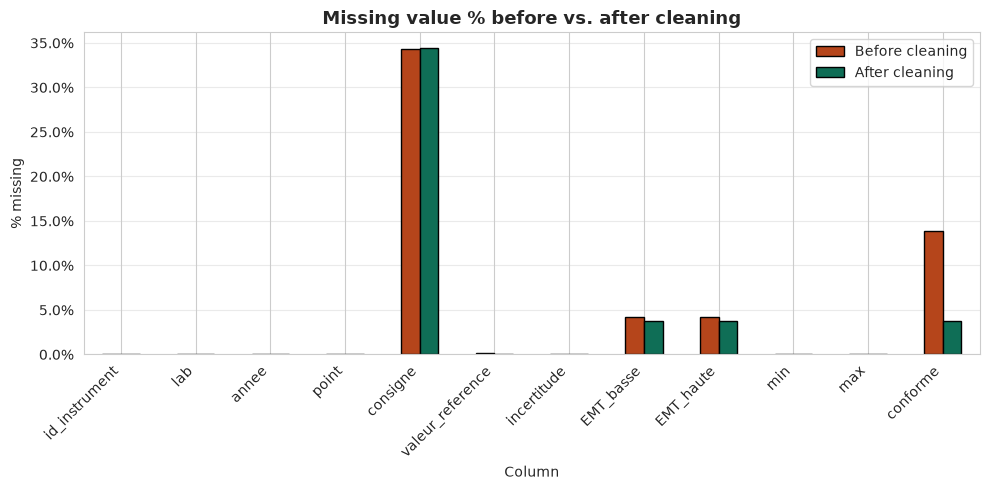

In [14]:
missing_before = df_raw.isna().mean() * 100
missing_after = df.reindex(columns=df_raw.columns).isna().mean() * 100

comp = pd.DataFrame({"missing_pct_before": missing_before, "missing_pct_after": missing_after}).fillna(0)

fig, ax = plt.subplots(figsize=(10, 5))
comp.plot(kind="bar", ax=ax, color=["#B5451B", "#0F6E56"], edgecolor="black")
ax.set_title("Missing value % before vs. after cleaning", fontsize=13, fontweight="bold")
ax.set_xlabel("Column")
ax.set_ylabel("% missing")
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.grid(axis="y", alpha=0.4)
ax.legend(["Before cleaning", "After cleaning"])
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(REPORTS_FIGURES / "01_missing_before_after.png", dpi=150)
plt.show()


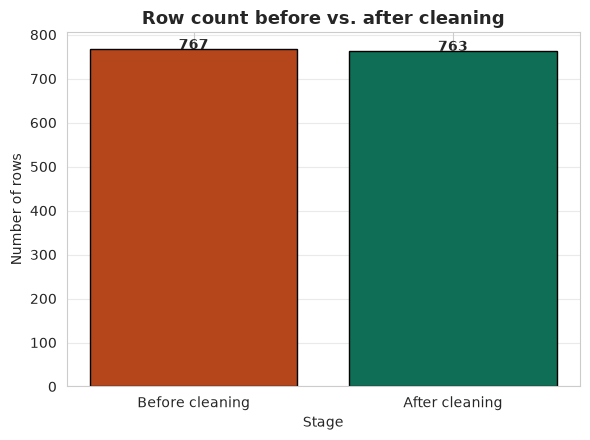

In [15]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.bar(["Before cleaning", "After cleaning"], [n_rows_start, n_after],
       color=["#B5451B", "#0F6E56"], edgecolor="black")
ax.set_title("Row count before vs. after cleaning", fontsize=13, fontweight="bold")
ax.set_xlabel("Stage")
ax.set_ylabel("Number of rows")
for i, v in enumerate([n_rows_start, n_after]):
    ax.text(i, v + 0.3, str(v), ha="center", fontweight="bold")
ax.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.savefig(REPORTS_FIGURES / "02_rowcount_before_after.png", dpi=150)
plt.show()


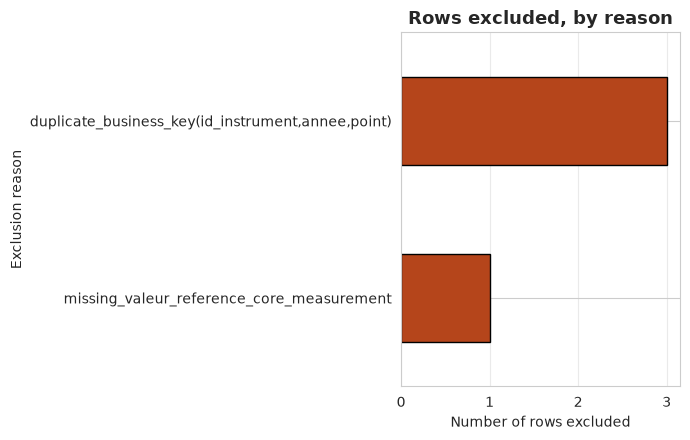

In [16]:
fig, ax = plt.subplots(figsize=(7, 4.5))
exclusion_counts = exclusion_df["exclusion_reason"].value_counts() if len(exclusion_df) else pd.Series(dtype=int)
if len(exclusion_counts):
    exclusion_counts.sort_values().plot(kind="barh", ax=ax, color="#B5451B", edgecolor="black")
    ax.set_title("Rows excluded, by reason", fontsize=13, fontweight="bold")
    ax.set_xlabel("Number of rows excluded")
    ax.set_ylabel("Exclusion reason")
    ax.grid(axis="x", alpha=0.4)
    plt.tight_layout()
    plt.savefig(REPORTS_FIGURES / "03_exclusions_by_reason.png", dpi=150)
    plt.show()
else:
    plt.close(fig)
    print("No exclusions to plot.")


---
## 7. Conclusions

This cell prints an automatic, data-driven summary — every figure is computed above,
nothing here is asserted without a corresponding computation.


In [17]:
print("=" * 70)
print("DATA CLEANING — AUTOMATIC SUMMARY")
print("=" * 70)
print(f"Rows before cleaning : {n_rows_start}")
print(f"Rows after cleaning  : {n_after}")
print(f"Rows excluded        : {len(exclusion_df)} ({round(len(exclusion_df) / n_rows_start * 100, 2)}%)")
print(f"Lab variants collapsed: {df_raw['lab'].nunique()} -> {df['lab_clean'].nunique()}")
print(f"'conforme' recomputed from EMT rule: {int(df['conforme_recomputed'].sum())} row(s)")
print(f"Outliers flagged (IQR)            : {int(df['outlier_iqr_valeur_reference'].sum())}")
print(f"Outliers flagged (per-instrument z): {int(df['outlier_zscore_per_instrument'].sum())}")
if len(exclusion_df):
    print("\nExclusion reasons:")
    for reason, count in exclusion_df["exclusion_reason"].value_counts().items():
        print(f"  - {reason}: {count}")
print("=" * 70)


DATA CLEANING — AUTOMATIC SUMMARY
Rows before cleaning : 767
Rows after cleaning  : 763
Rows excluded        : 4 (0.52%)
Lab variants collapsed: 37 -> 20
'conforme' recomputed from EMT rule: 74 row(s)
Outliers flagged (IQR)            : 46
Outliers flagged (per-instrument z): 3

Exclusion reasons:
  - duplicate_business_key(id_instrument,annee,point): 3
  - missing_valeur_reference_core_measurement: 1


---
**End of Notebook 02 — Data Cleaning.**

Outputs generated:
- `data/processed/ILA_cleaned.csv`
- `reports/quality/cleaning_exclusions_log.csv` (if any rows were excluded)
- `reports/quality/cleaning_summary.xlsx`
- Figures under `reports/figures/02_data_cleaning/`
- `logs/02_data_cleaning.log`

Next: **Notebook 03 — Exploratory Data Analysis, Statistical Analysis & Time-Series Analysis.**
